In [178]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [179]:


midfielders = pd.read_csv(
    "data\processed\ midfielders_similarity_ready.csv"
)

forwards = pd.read_csv(
    "data\processed\ forwards_similarity_ready.csv"
)

defenders = pd.read_csv(
    "data\processed\ defenders_similarity_ready.csv"
)

position_data = {
    "Midfielder": midfielders,
    "Forward": forwards,
    "Defender": defenders
}



<>:2: SyntaxWarning: invalid escape sequence '\p'
<>:6: SyntaxWarning: invalid escape sequence '\p'
<>:10: SyntaxWarning: invalid escape sequence '\p'
<>:2: SyntaxWarning: invalid escape sequence '\p'
<>:6: SyntaxWarning: invalid escape sequence '\p'
<>:10: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\511898791.py:2: SyntaxWarning: invalid escape sequence '\p'
  "data\processed\ midfielders_similarity_ready.csv"
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\511898791.py:6: SyntaxWarning: invalid escape sequence '\p'
  "data\processed\ forwards_similarity_ready.csv"
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\511898791.py:10: SyntaxWarning: invalid escape sequence '\p'
  "data\processed\ defenders_similarity_ready.csv"
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\511898791.py:1: DtypeWarning: Columns (0: weak_foot) have mixed types. Specify dtype option on import or set low_memory=False.
  midfielders = pd.read_csv(


In [180]:

midfielder_features = [
    #Scoring
    "goals_per90",
    "xg_per90",

    #Chance Creation
    "assists_per90",
    "xag_per90",
    "per_90_minutes_kp",
    "sca_sca90",

    #Progression
    "per_90_minutes_prgp",
    "per_90_minutes_prgc",
    "per_90_minutes_1_per_3",
    "per_90_minutes_ppa",


    #Possession/passing
    "pass_completion_pct",

    #Defense
    "per_90_minutes_tackles_tkl",
    "per_90_minutes_int"

]

forward_features = [
    # Scoring
    "goals_per90",
    "xg_per90",

    # Chance Creation
    "assists_per90",
    "xag_per90",
    "per_90_minutes_kp",
    "sca_sca90",

    # Progression / Attacking
    "per_90_minutes_prgc",
    "per_90_minutes_ppa",

    # Possession
    "pass_completion_pct",

    # Defensive Work
    "per_90_minutes_tackles_tkl",
    "per_90_minutes_int"
]

defender_features = [
    # Defensive Contribution
    "per_90_minutes_tackles_tkl",
    "per_90_minutes_int",

    # Passing
    "pass_completion_pct",

    # Progression
    "per_90_minutes_prgp",
    "per_90_minutes_prgc",
    "per_90_minutes_1_per_3",

    # Attacking Contribution
    "assists_per90",
    "xag_per90",
    "per_90_minutes_kp",

    # Optional scoring contribution
    "goals_per90",
    "xg_per90"
]

POSITION_FEATURES = {
    "Midfielder": midfielder_features,
    "Forward": forward_features,
    "Defender": defender_features
}

position_data = {
    "Midfielder": midfielders,
    "Forward": forwards,
    "Defender": defenders
}



In [181]:
POSITION_SCORING_CATEGORIES = {

    "Midfielder": {

        "attacking": [
            "goals_per90",
            "xg_per90"
        ],

        "chance_creation": [
            "assists_per90",
            "xag_per90",
            "per_90_minutes_kp",
            "sca_sca90"
        ],

        "progression": [
            "per_90_minutes_prgp",
            "per_90_minutes_prgc",
            "per_90_minutes_1_per_3",
            "per_90_minutes_ppa"
        ],

        "possession": [
            "pass_completion_pct"
        ],

        "defending": [
            "per_90_minutes_tackles_tkl",
            "per_90_minutes_int"
        ]
    },


    "Forward": {

        "attacking": [
            "goals_per90",
            "xg_per90"
        ],

        "chance_creation": [
            "assists_per90",
            "xag_per90",
            "per_90_minutes_kp",
            "sca_sca90"
        ],

        "progression": [
            "per_90_minutes_prgc",
            "per_90_minutes_ppa"
        ],

        "possession": [
            "pass_completion_pct"
        ],

        "defending": [
            "per_90_minutes_tackles_tkl",
            "per_90_minutes_int"
        ]
    },


    "Defender": {

        "attacking": [
            "goals_per90",
            "xg_per90"
        ],

        "chance_creation": [
            "assists_per90",
            "xag_per90",
            "per_90_minutes_kp"
        ],

        "progression": [
            "per_90_minutes_prgp",
            "per_90_minutes_prgc",
            "per_90_minutes_1_per_3"
        ],

        "possession": [
            "pass_completion_pct"
        ],

        "defending": [
            "per_90_minutes_tackles_tkl",
            "per_90_minutes_int"
        ]
    }
}

In [182]:
POSITION_FEATURES = {
    "Midfielder": midfielder_features,
    "Forward": forward_features,
    "Defender": defender_features
}

for position, dataframe in position_data.items():

    features = POSITION_FEATURES[position]

    dataframe["data_completeness"] = (
        dataframe[features]
        .notna()
        .mean(axis=1)
        .mul(100)
    )

    print(
        f"\n{position} completeness:"
    )

    print(
        dataframe[
            "data_completeness"
        ].describe()
    )



Midfielder completeness:
count    7874.000000
mean       87.775737
std        28.122375
min        15.384615
25%       100.000000
50%       100.000000
75%       100.000000
max       100.000000
Name: data_completeness, dtype: float64

Forward completeness:
count    5723.000000
mean       92.719966
std        21.830821
min        18.181818
25%       100.000000
50%       100.000000
75%       100.000000
max       100.000000
Name: data_completeness, dtype: float64

Defender completeness:
count    9525.000000
mean       89.923169
std        25.136682
min        18.181818
25%       100.000000
50%       100.000000
75%       100.000000
max       100.000000
Name: data_completeness, dtype: float64


C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\3174902102.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe["data_completeness"] = (
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\3174902102.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe["data_completeness"] = (
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\3174902102.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all 

In [183]:
for position, dataframe in position_data.items():

    features = POSITION_FEATURES[position]

    for feature in features:

        # Season median first
        dataframe[feature] = (
            dataframe[feature]
            .fillna(
                dataframe
                .groupby("season")[feature]
                .transform("median")
            )
        )

        # Global position median fallback
        dataframe[feature] = (
            dataframe[feature]
            .fillna(
                dataframe[feature].median()
            )
        )

In [184]:
# Recalculate feature percentiles after imputation

for position, dataframe in position_data.items():

    features = POSITION_FEATURES[position]

    for feature in features:

        percentile_col = (
            feature + "_percentile"
        )

        dataframe[percentile_col] = (
            dataframe
            .groupby("season")[feature]
            .rank(
                pct=True
            )
            .mul(100)
        )

    print(
        f"{position} percentiles recalculated."
    )

Midfielder percentiles recalculated.
Forward percentiles recalculated.
Defender percentiles recalculated.


In [185]:
#Creating category scores
for position, dataframe in position_data.items():

    categories = (
        POSITION_SCORING_CATEGORIES[position]
    )

    for category, features in categories.items():

        percentile_cols = [
            feature + "_percentile"
            for feature in features
        ]

        score_name = {
            "attacking": "attacking_score",
            "chance_creation": "creation_score",
            "progression": "progression_score",
            "possession": "possession_score",
            "defending": "defending_score"
        }[category]

        dataframe[score_name] = (
            dataframe[
                percentile_cols
            ].mean(axis=1)
        )

C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\3514710717.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe[score_name] = (
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\3514710717.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe[score_name] = (
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\3514710717.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once us

In [186]:
score_columns = [
    "attacking_score",
    "creation_score",
    "progression_score",
    "possession_score",
    "defending_score"
]

print(
    forwards[
        score_columns
    ].isna().sum()
)

attacking_score      0
creation_score       0
progression_score    0
possession_score     0
defending_score      0
dtype: int64


In [187]:
#Make overall score archetype-aware
archetype_weights = {

    "Creative / Progressive Midfielder": {
        "attacking_score": 0.20,
        "creation_score": 0.30,
        "progression_score": 0.25,
        "possession_score": 0.15,
        "defending_score": 0.10
    },

    "Defensive / Holding Midfielder": {
        "attacking_score": 0.10,
        "creation_score": 0.10,
        "progression_score": 0.20,
        "possession_score": 0.25,
        "defending_score": 0.35
    },

    "Direct / Finishing Forward": {
        "attacking_score": 0.45,
        "creation_score": 0.20,
        "progression_score": 0.15,
        "possession_score": 0.10,
        "defending_score": 0.10
    },

    "Creative / Progressive Forward": {
        "attacking_score": 0.25,
        "creation_score": 0.35,
        "progression_score": 0.25,
        "possession_score": 0.10,
        "defending_score": 0.05
    },

        "Attacking / Progressive Defender": {
        "attacking_score": 0.10,
        "creation_score": 0.25,
        "progression_score": 0.30,
        "possession_score": 0.15,
        "defending_score": 0.20
    },

    "Defensive / Central Defender": {
        "attacking_score": 0.05,
        "creation_score": 0.05,
        "progression_score": 0.15,
        "possession_score": 0.25,
        "defending_score": 0.50
    }
}




In [188]:
def calculate_performance_score(row):

    weights = archetype_weights.get(
        row["archetype"]
    )

    if weights is None:
        return np.nan

    score = sum(
        row[category] * weight
        for category, weight
        in weights.items()
    )

    return score

In [189]:
for position, dataframe in position_data.items():

    dataframe[
        "performance_score"
    ] = dataframe.apply(
        calculate_performance_score,
        axis=1
    )

C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\3791971704.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe[
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\3791971704.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe[
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\3791971704.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To

In [190]:
for position, dataframe in position_data.items():

    dataframe["archetype_rank"] = (
        dataframe
        .groupby(
            [
                "season",
                "archetype"
            ]
        )["performance_score"]
        .rank(
            ascending=False,
            method="min"
        )
    )

    dataframe[
        "performance_percentile"
    ] = (
        dataframe
        .groupby(
            [
                "season",
                "archetype"
            ]
        )["performance_score"]
        .rank(
            pct=True
        )
        .mul(100)
    )

C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\2739424742.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe["archetype_rank"] = (
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\2739424742.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe[
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\2739424742.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.conc

In [191]:
for position, scoring_df in position_data.items():

    duplicates = scoring_df[
        scoring_df.duplicated(
            subset=[
                "player",
                "team",
                "season"
            ],
            keep=False
        )
    ]

    print(
        f"\n===== {position} ====="
    )

    print(
        "Duplicate rows:",
        len(duplicates)
    )

    if not duplicates.empty:

        print(
            duplicates[
                [
                    "player",
                    "team",
                    "season",
                    "archetype",
                    "performance_score"
                ]
            ].sort_values(
                [
                    "player",
                    "season"
                ]
            )
        )


===== Midfielder =====
Duplicate rows: 0

===== Forward =====
Duplicate rows: 0

===== Defender =====
Duplicate rows: 0


In [192]:
duplicate_key = ["player", "team", "season"]

check_cols = [
    "minutes",
    "player_positions",
    "overall",
    "age_fbref",
    "age_fifa"
] + midfielder_features

duplicate_rows = scoring_df[
    scoring_df.duplicated(
        subset=duplicate_key,
        keep=False
    )
].copy()

variation = (
    duplicate_rows
    .groupby(duplicate_key)[check_cols]
    .nunique(dropna=False)
)

different_duplicates = variation[
    (variation > 1).any(axis=1)
]

print(
    "Duplicate groups with different data:",
    len(different_duplicates)
)

print(different_duplicates.head(20))

Duplicate groups with different data: 0
Empty DataFrame
Columns: [minutes, player_positions, overall, age_fbref, age_fifa, goals_per90, xg_per90, assists_per90, xag_per90, per_90_minutes_kp, sca_sca90, per_90_minutes_prgp, per_90_minutes_prgc, per_90_minutes_1_per_3, per_90_minutes_ppa, pass_completion_pct, per_90_minutes_tackles_tkl, per_90_minutes_int]
Index: []


In [193]:
different_keys = (
    different_duplicates
    .reset_index()[
        ["player", "team", "season"]
    ]
)

for _, row in different_keys.head(10).iterrows():

    print(
        scoring_df[
            (scoring_df["player"] == row["player"]) &
            (scoring_df["team"] == row["team"]) &
            (scoring_df["season"] == row["season"])
        ][
            [
                "player",
                "team",
                "season",
                "minutes",
                "player_positions",
                "overall",
                "data_completeness_pct",
                "performance_score"
            ]
        ]
    )

    print()

In [194]:
def score_confidence(completeness):

    if completeness >= 95:
        return "High"
    elif completeness >= 75:
        return "Moderate"
    elif completeness >= 50:
        return "Low"
    else:
        return "Insufficient"


for position, dataframe in position_data.items():

    dataframe["score_confidence"] = (
        dataframe[
            "data_completeness"
        ]
        .apply(score_confidence)
    )

C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\419641059.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe["score_confidence"] = (
C:\Users\Titus\AppData\Local\Temp\ipykernel_27016\419641059.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe["score_confidence"] = (


In [195]:
#Player lookup function
def get_player_score(
    player_name,
    position,
    position_data,
    season=None
):

    dataframe = position_data[position]

    player_rows = dataframe[
        dataframe["player"].str.lower()
        == player_name.lower()
    ]

    if player_rows.empty:
        raise ValueError(
            f"{player_name} not found in {position} data."
        )

    if season is not None:

        season_rows = player_rows[
            player_rows["season"] == season
        ]

        if season_rows.empty:
            available_seasons = (
                player_rows["season"]
                .dropna()
                .sort_values()
                .unique()
            )

            raise ValueError(
                f"{player_name} does not have data "
                f"for season {season}. "
                f"Available seasons: {available_seasons}"
            )

        player_rows = season_rows

    player_row = (
        player_rows
        .sort_values(
            "season",
            ascending=False
        )
        .iloc[0]
    )

    return player_row[
        [
            "player",
            "team",
            "season",
            "player_positions",
            "archetype",
            "performance_score",
            "performance_percentile",
            "archetype_rank",
            "data_completeness",
            "score_confidence",
            "attacking_score",
            "creation_score",
            "progression_score",
            "possession_score",
            "defending_score"
        ]
    ]



In [196]:
#testing De Bruyne player score
get_player_score(
    "Kevin De Bruyne",
    "Midfielder",
    position_data,
    season=None

)

player                                      Kevin De Bruyne
team                                        Manchester City
season                                                 2425
player_positions                                         CM
archetype                 Creative / Progressive Midfielder
performance_score                                 73.376623
performance_percentile                             83.59375
archetype_rank                                         43.0
data_completeness                                     100.0
score_confidence                                       High
attacking_score                                   84.902597
creation_score                                    98.555195
progression_score                                 88.474026
possession_score                                  24.090909
defending_score                                   10.974026
Name: 4129, dtype: object

In [197]:
#testing Ronaldo player score
get_player_score(
    "Cristiano Ronaldo",
    "Forward",
    position_data,
    season=2223
)

player                             Cristiano Ronaldo
team                                  Manchester Utd
season                                          2223
player_positions                                  ST
archetype                 Direct / Finishing Forward
performance_score                          34.735607
performance_percentile                     19.389587
archetype_rank                                 450.0
data_completeness                              100.0
score_confidence                                High
attacking_score                            41.395494
creation_score                             19.148936
progression_score                           20.77597
possession_score                           72.778473
defending_score                            18.836045
Name: 1109, dtype: object

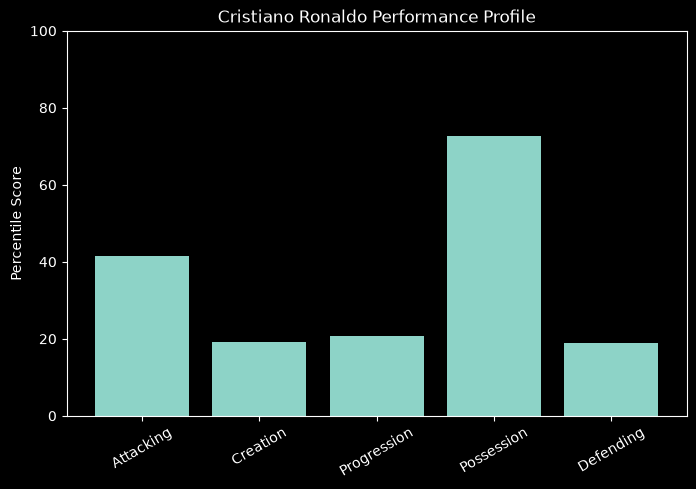

In [198]:
player = get_player_score(
    "Cristiano Ronaldo",
    "Forward",
    position_data,
    season=2223
)

categories = [
    "Attacking",
    "Creation",
    "Progression",
    "Possession",
    "Defending"
]

scores = [
    player["attacking_score"],
    player["creation_score"],
    player["progression_score"],
    player["possession_score"],
    player["defending_score"]
]

plt.figure(figsize=(8, 5))

plt.bar(
    categories,
    scores
)

plt.ylim(0, 100)

plt.ylabel("Percentile Score")

plt.title(
    f"{player['player']} Performance Profile"
)

plt.xticks(rotation=30)

plt.show()

In [199]:
#scoring_df.to_csv(
    #"midfielders_scored.csv", index=False)

for position, dataframe in position_data.items():

    filename = (
        f"data/processed/ "
        f"{position.lower()}s_scored.csv"
    )

    dataframe.to_csv(
        filename,
        index=False
    )

    print(
        f"Saved {position}: {filename}"
    )


Saved Midfielder: data/processed/ midfielders_scored.csv
Saved Forward: data/processed/ forwards_scored.csv
Saved Defender: data/processed/ defenders_scored.csv
